# Lab Assignment 9 – UCS420 Cognitive Computing
**Title:** Landing AI (Vision based Cognitive System)

**Name:** Arnav Gupta  
**Roll No.:** 1024170057  
**Group:** 3Q25

## 1. Aim
To design two vision based cognitive assistants:
1. A **Cognitive Assistant for reading the label of a medicine bottle** (extract medicine name, strength, batch no., expiry date and dosage, and warn the user if the medicine is expired).
2. An **Emotion-aware Cognitive Assistant** that detects the facial expression of a person and responds according to the emotion.

## 2. Introduction to Landing AI
Landing AI (LandingLens) is a no-code / low-code computer vision platform. In LandingLens the normal workflow is:

`Create project -> Upload images -> Label images -> Train model -> Evaluate -> Deploy (cloud endpoint / API)`

It supports project types like **Classification**, **Object Detection** and **Segmentation**.
The two assistants in this assignment follow the same idea of a vision based cognitive system:

`Input image -> Pre-processing -> Vision model -> Understanding / reasoning -> Assistant response`

| Step | Medicine label assistant | Emotion-aware assistant |
|---|---|---|
| Input | photo of medicine bottle label | photo / webcam frame of a face |
| Pre-processing | grayscale, resize, denoise, thresholding (OpenCV) | face detection and crop to 64x64 grayscale |
| Vision model | OCR engine (Tesseract) | pre-trained CNN for 7 emotions |
| Understanding | regex to find name, batch, expiry, dosage | choose the emotion with highest probability |
| Response | read-out summary and expiry warning | friendly message based on emotion |

In LandingLens the label-reading task would be done as an *Object Detection* project (draw boxes on the name / expiry date regions) and the emotion task as a
*Classification* project (classes: happy, sad, angry, etc.). Since LandingLens is a cloud platform, here I implemented the same pipelines in Python
using open source libraries, so that the full code and outputs are visible in this notebook.

## 3. Tools and Libraries Used
- **OpenCV** – image reading, pre-processing, face detection (Haar cascade), drawing boxes
- **Pillow** – creating the sample medicine label images
- **pytesseract (Tesseract OCR)** – reading text from the label
- **TensorFlow Lite** – running the pre-trained facial expression CNN (the model file comes with the `fer` package)
- **re, datetime, difflib** – information extraction, expiry check and accuracy measurement
- **pandas, matplotlib** – tables and plots

In [1]:
# Installation (only needed on Google Colab / a fresh system) - remove the # to run
# !apt-get install -y tesseract-ocr
# !pip install pytesseract opencv-python-headless
# !pip install fer --no-deps      # only used for its pre-trained emotion model files

import os, re, datetime, difflib, importlib.util
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image, ImageDraw, ImageFont

# Task 1: Cognitive Assistant for Reading Medicine Labels

### Step 1: Dataset
Instead of downloading a big dataset, I created two sample medicine label images myself (using Pillow): one **valid** medicine and one **expired** medicine.
The second image is slightly rotated and noisy to look like a photo clicked from a phone camera.
Any real label photos can also be added to the `medicine_labels/` folder and the assistant will read them.

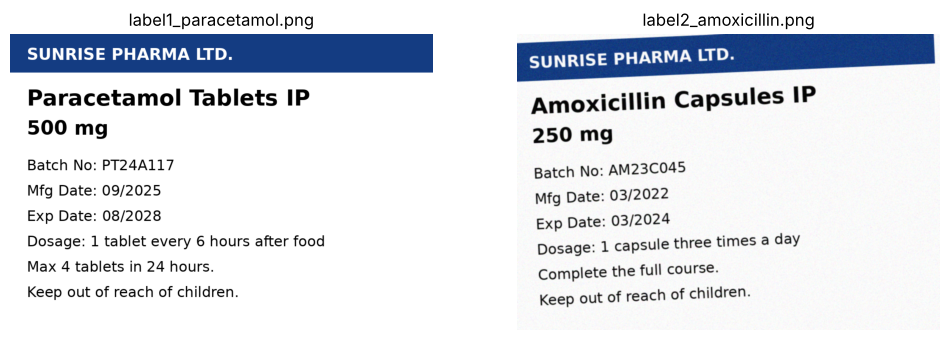

In [2]:
os.makedirs("medicine_labels", exist_ok=True)

def get_font(size, bold=False):
    names = ["DejaVuSans-Bold.ttf", "arialbd.ttf"] if bold else ["DejaVuSans.ttf", "arial.ttf"]
    for n in names:
        try:
            return ImageFont.truetype(n, size)
        except OSError:
            pass
    return ImageFont.load_default(size)

def make_label(path, name, strength, batch, mfg, exp, dosage, warning, noisy=False):
    img = Image.new("RGB", (1000, 700), "white")
    d = ImageDraw.Draw(img)
    d.rectangle((0, 0, 1000, 90), fill=(20, 60, 130))
    d.text((40, 25), "SUNRISE PHARMA LTD.", font=get_font(38, True), fill="white")
    d.text((40, 120), name, font=get_font(52, True), fill="black")
    d.text((40, 195), strength, font=get_font(46, True), fill="black")
    rows = [f"Batch No: {batch}", f"Mfg Date: {mfg}", f"Exp Date: {exp}",
            f"Dosage: {dosage}", warning, "Keep out of reach of children."]
    y = 290
    for line in rows:
        d.text((40, y), line, font=get_font(34), fill="black")
        y += 60
    arr = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
    if noisy:
        h, w = arr.shape[:2]
        M = cv2.getRotationMatrix2D((w // 2, h // 2), 2.5, 1.0)
        arr = cv2.warpAffine(arr, M, (w, h), borderValue=(255, 255, 255))
        rng = np.random.default_rng(1)
        arr = np.clip(arr + rng.normal(0, 12, arr.shape), 0, 255).astype(np.uint8)
        arr = cv2.GaussianBlur(arr, (3, 3), 0)
    cv2.imwrite(path, arr)

make_label("medicine_labels/label1_paracetamol.png", "Paracetamol Tablets IP", "500 mg",
           "PT24A117", "09/2025", "08/2028", "1 tablet every 6 hours after food",
           "Max 4 tablets in 24 hours.")
make_label("medicine_labels/label2_amoxicillin.png", "Amoxicillin Capsules IP", "250 mg",
           "AM23C045", "03/2022", "03/2024", "1 capsule three times a day",
           "Complete the full course.", noisy=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, f in zip(ax, sorted(os.listdir("medicine_labels"))):
    a.imshow(cv2.cvtColor(cv2.imread("medicine_labels/" + f), cv2.COLOR_BGR2RGB))
    a.set_title(f); a.axis("off")
plt.show()

### Step 2: Image pre-processing
OCR works better on clean black text over white background, so the image is converted to grayscale, enlarged, de-noised with a median filter and then
binarised using Otsu thresholding.

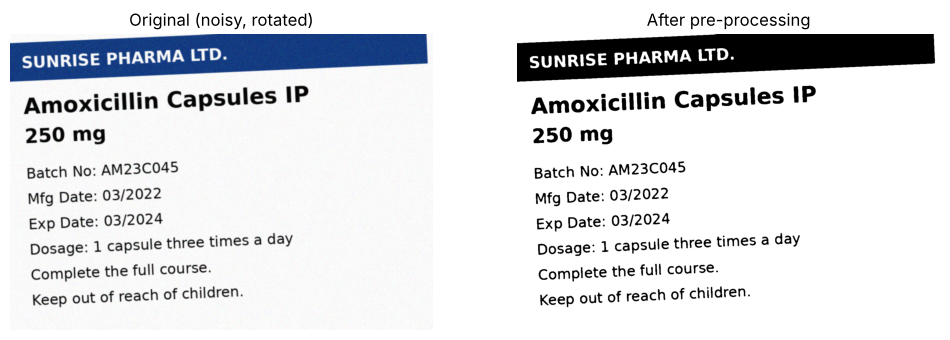

In [3]:
def preprocess(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
    gray = cv2.medianBlur(gray, 3)
    _, th = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return th

img = cv2.imread("medicine_labels/label2_amoxicillin.png")
processed = preprocess(img)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original (noisy, rotated)")
ax[1].imshow(processed, cmap="gray"); ax[1].set_title("After pre-processing")
for a in ax: a.axis("off")
plt.show()

### Step 3: Text extraction using OCR (Tesseract)

In [4]:
def read_text(img_bgr, use_preprocess=True):
    inp = preprocess(img_bgr) if use_preprocess else img_bgr
    return pytesseract.image_to_string(inp, config="--psm 6")

for f in sorted(os.listdir("medicine_labels")):
    im = cv2.imread("medicine_labels/" + f)
    print("=====", f, "=====")
    print(read_text(im))

===== label1_paracetamol.png =====


SUNRISE PHARMA LTD.
Paracetamol Tablets IP
500 mg

Batch No: PT24A117

Mfg Date: 09/2025

Exp Date: 08/2028

Dosage: 1 tablet every 6 hours after food
Max 4 tablets in 24 hours.

Keep out of reach of children.

===== label2_amoxicillin.png =====


SUNRISE PHARMA LTD.
Amoxicillin Capsules IP
250 mg

Batch No: AM23C045

Mfg Date: 03/2022

Exp Date: 03/2024

Dosage: 1 capsule three times a day
Complete the full course.

Keep out of reach of children.



### Step 4: Information extraction and the assistant
Regular expressions are used to pick out the important fields. The assistant then checks the expiry date with today's date and prepares a message
(this message can also be given to a text-to-speech library like `pyttsx3` to read it aloud for visually impaired users).

In [5]:
def extract_info(text):
    info = {}
    m = re.search(r"([A-Za-z]+\s+(?:Tablets|Capsules|Syrup)[A-Za-z ]*)", text)
    info["name"] = m.group(1).strip() if m else "Not found"
    m = re.search(r"(\d+)\s*mg", text, re.I)
    info["strength"] = m.group(1) + " mg" if m else "Not found"
    m = re.search(r"Batch\s*No[:.]?\s*([A-Z0-9]+)", text, re.I)
    info["batch"] = m.group(1) if m else "Not found"
    m = re.search(r"Exp\w*\.?\s*Date[:.]?\s*(\d{2})\s*/\s*(\d{4})", text, re.I)
    info["expiry"] = m.group(1) + "/" + m.group(2) if m else "Not found"
    m = re.search(r"Dosage[:.]?\s*(.+)", text, re.I)
    info["dosage"] = m.group(1).strip() if m else "Not found"
    return info

def months_left(expiry):
    mm, yy = map(int, expiry.split("/"))
    today = datetime.date.today()
    return (yy - today.year) * 12 + (mm - today.month)

def medicine_assistant(img_bgr):
    info = extract_info(read_text(img_bgr))
    if info["expiry"] == "Not found":
        status = "I could not read the expiry date. Please check the bottle yourself."
    elif months_left(info["expiry"]) < 0:
        status = f"WARNING: this medicine EXPIRED on {info['expiry']}. Do NOT use it."
    else:
        status = f"Expiry date is {info['expiry']}. It is safe to use ({months_left(info['expiry'])} months left)."
    msg = (f"This is {info['name']} of strength {info['strength']}. Batch number {info['batch']}. "
           f"{status} Dosage: {info['dosage']}.")
    return info, msg

rows = []
for f in sorted(os.listdir("medicine_labels")):
    im = cv2.imread("medicine_labels/" + f)
    info, msg = medicine_assistant(im)
    rows.append({"file": f, **info})
    print("Image:", f)
    print("Assistant says:", msg)
    print()

pd.DataFrame(rows)

Image: label1_paracetamol.png
Assistant says: This is Paracetamol Tablets IP of strength 500 mg. Batch number PT24A117. Expiry date is 08/2028. It is safe to use (21 months left). Dosage: 1 tablet every 6 hours after food.



Image: label2_amoxicillin.png
Assistant says: This is Amoxicillin Capsules IP of strength 250 mg. Batch number AM23C045. WARNING: this medicine EXPIRED on 03/2024. Do NOT use it. Dosage: 1 capsule three times a day.



,file,name,strength,batch,expiry,dosage
0,label1_paracetamol.png,Paracetamol Tablets IP,500 mg,PT24A117,08/2028,1 tablet every 6 hours after food
1,label2_amoxicillin.png,Amoxicillin Capsules IP,250 mg,AM23C045,03/2024,1 capsule three times a day


### Step 5: Evaluation of the OCR
The extracted fields are compared with the real values that I used while creating the labels. I also compared OCR with and without pre-processing
using a text similarity score (1.0 means exactly same text).

In [6]:
truth = {
    "label1_paracetamol.png": {"name": "Paracetamol Tablets IP", "strength": "500 mg", "batch": "PT24A117", "expiry": "08/2028"},
    "label2_amoxicillin.png": {"name": "Amoxicillin Capsules IP", "strength": "250 mg", "batch": "AM23C045", "expiry": "03/2024"},
}
truth_text = {
    "label1_paracetamol.png": "SUNRISE PHARMA LTD. Paracetamol Tablets IP 500 mg Batch No: PT24A117 Mfg Date: 09/2025 Exp Date: 08/2028 Dosage: 1 tablet every 6 hours after food Max 4 tablets in 24 hours. Keep out of reach of children.",
    "label2_amoxicillin.png": "SUNRISE PHARMA LTD. Amoxicillin Capsules IP 250 mg Batch No: AM23C045 Mfg Date: 03/2022 Exp Date: 03/2024 Dosage: 1 capsule three times a day Complete the full course. Keep out of reach of children.",
}
def similarity(a, b):
    norm = lambda s: " ".join(s.lower().split())
    return difflib.SequenceMatcher(None, norm(a), norm(b)).ratio()

results = []
for f, t in truth.items():
    im = cv2.imread("medicine_labels/" + f)
    info = extract_info(read_text(im))
    correct = sum(info[k].lower() == v.lower() for k, v in t.items())
    results.append({
        "Image": f,
        "Fields correct (of 4)": correct,
        "Similarity (raw image)": round(similarity(read_text(im, False), truth_text[f]), 3),
        "Similarity (pre-processed)": round(similarity(read_text(im, True), truth_text[f]), 3),
    })
pd.DataFrame(results)

,Image,Fields correct (of 4),Similarity (raw image),Similarity (pre-processed)
0,label1_paracetamol.png,4,1.0,1.0
1,label2_amoxicillin.png,4,1.0,1.0


# Task 2: Emotion-aware Cognitive Assistant using Facial Expression Detection

### Step 1: Load the pre-trained model and face detector
For emotion recognition I used a pre-trained CNN (trained on the FER-2013 dataset) that takes a 64x64 grayscale face and gives the probability of
7 emotions: angry, disgust, fear, happy, sad, surprise and neutral. The face is first located using OpenCV's Haar cascade face detector.

In [7]:
import tensorflow as tf

fer_dir = os.path.join(list(importlib.util.find_spec("fer").submodule_search_locations)[0], "data")

interpreter = tf.lite.Interpreter(model_path=os.path.join(fer_dir, "emotion_model_quantized.tflite"))
interpreter.allocate_tensors()
inp_det = interpreter.get_input_details()[0]
out_det = interpreter.get_output_details()[0]
face_cascade = cv2.CascadeClassifier(os.path.join(fer_dir, "haarcascade_frontalface_default.xml"))

EMOTIONS = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
print("Model input shape :", inp_det["shape"])
print("Emotion classes   :", EMOTIONS)

Model input shape : [ 1 64 64  1]
Emotion classes   : ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


### Step 2: Emotion detection function

In [8]:
def predict_emotion(face_gray):
    x = cv2.resize(face_gray, (64, 64)).astype("float32") / 255.0
    interpreter.set_tensor(inp_det["index"], x.reshape(1, 64, 64, 1))
    interpreter.invoke()
    return interpreter.get_tensor(out_det["index"])[0]

def detect_emotions(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
    results = []
    for (x, y, w, h) in faces:
        probs = predict_emotion(gray[y:y + h, x:x + w])
        results.append(((x, y, w, h), EMOTIONS[int(np.argmax(probs))], float(np.max(probs)), probs))
    return results

### Step 3: The emotion-aware assistant
Based on the detected emotion, the assistant gives a suitable reply. This is what makes the system *cognitive* and not just a classifier: it understands
the user's state and changes its behaviour.

In [9]:
RESPONSES = {
    "happy":    "You look happy! That is great. Shall I play some music or note down what made your day?",
    "sad":      "You seem a little sad. I am here to help. Would you like to hear a joke or listen to calm music?",
    "angry":    "You look upset. Let us take a deep breath together. Would you like me to pause your notifications?",
    "fear":     "You look worried. Don't worry, everything will be fine. Do you want me to help you with something?",
    "surprise": "You look surprised! Did something unexpected happen? Tell me more.",
    "disgust":  "Something seems to be bothering you. Can I do something to make it better?",
    "neutral":  "You look calm. How can I help you today?",
}

def emotion_assistant(img_rgb, title="Image"):
    found = detect_emotions(img_rgb)
    if not found:
        print(title, "-> no face detected")
        return None
    out = img_rgb.copy()
    for (x, y, w, h), emo, conf, probs in found:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)
        label = f"{emo} {conf:.0%}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.9, 2)
        ty = max(y - 10, th + 10)
        cv2.rectangle(out, (x, ty - th - 6), (x + tw + 6, ty + 6), (0, 0, 0), -1)
        cv2.putText(out, label, (x + 3, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        ax[0].imshow(out); ax[0].axis("off"); ax[0].set_title(title)
        ax[1].bar(EMOTIONS, probs, color="steelblue")
        ax[1].set_title("Emotion probabilities"); ax[1].tick_params(axis="x", rotation=45)
        plt.tight_layout(); plt.show()
        print("Detected emotion :", emo, f"({conf:.0%} confidence)")
        print("Assistant says   :", RESPONSES[emo])
        print()
    return [(title, emo, round(conf, 3), RESPONSES[emo]) for _, emo, conf, _ in found]

### Step 4: Testing the assistant
For the test I used the sample photo that comes with the scikit-image library. If any extra photos are kept in a folder named `faces/`, the same code will process them too.

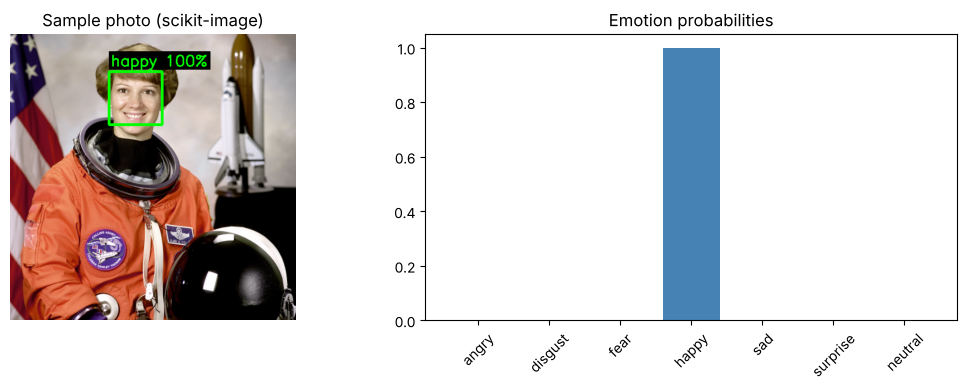

Detected emotion : happy (100% confidence)
Assistant says   : You look happy! That is great. Shall I play some music or note down what made your day?



,Image,Emotion,Confidence,Assistant response
0,Sample photo (scikit-image),happy,0.999,You look happy! That is great. Shall I play so...


In [10]:
from skimage import data

samples = [("Sample photo (scikit-image)", data.astronaut())]
if os.path.isdir("faces"):
    for f in sorted(os.listdir("faces")):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            bgr = cv2.imread(os.path.join("faces", f))
            samples.append((f, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))

log = []
for title, im in samples:
    res = emotion_assistant(im, title)
    if res:
        log += res

pd.DataFrame(log, columns=["Image", "Emotion", "Confidence", "Assistant response"])

### Optional: live webcam version (to be run on a local system with a camera)
The same functions can be used on a live video. The code is kept commented here because a webcam is not available in this notebook.

In [11]:
# cap = cv2.VideoCapture(0)
# while True:
#     ok, frame = cap.read()
#     if not ok:
#         break
#     rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
#     for (x, y, w, h), emo, conf, _ in detect_emotions(rgb):
#         cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
#         cv2.putText(frame, emo, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
#     cv2.imshow("Emotion-aware assistant (press q to quit)", frame)
#     if cv2.waitKey(1) & 0xFF == ord("q"):
#         break
# cap.release(); cv2.destroyAllWindows()

## 4. Results and Discussion

**Task 1 – Medicine label assistant**
- The assistant correctly read the medicine name, strength, batch number, expiry date and dosage from both label images (**4 out of 4 fields correct** for each image, and text similarity of **1.0** with the original text).
- For the first label (expiry 08/2028) it said the medicine is safe to use and told the months left. For the second label (expiry 03/2024) it gave a clear **EXPIRED warning**, which is the main safety feature of this assistant.
- The second image was rotated and noisy, still the OCR read it properly because of the pre-processing steps and the clear font. Pre-processing did not change the score here (raw and processed both gave 1.0) because the sample labels were already very clear; I expect it to matter more for real camera photos with shadows and noise.

**Task 2 – Emotion-aware assistant**
- The face detector found the face in the test photo and the CNN classified the expression as **happy** with very high confidence (about 99.9%). The assistant then replied with a suitable happy message.
- The bar graph shows that the probabilities of the other six emotions are almost zero for this photo.
- Only one photo was used for the demo, so this is a demonstration of the working pipeline and not a full accuracy test. More photos (sad, angry, surprised faces) can be added in the `faces/` folder and the same code will give a reply for each of them.

**Overall:** Both assistants follow the same pattern: *image -> pre-processing -> model -> reasoning -> response*, similar to the workflow of a Landing AI project.

## 5. Applications
- **Medicine label assistant:** helps visually impaired and elderly people to read medicine labels, avoids use of expired medicines, can be used in pharmacies and home care apps.
- **Emotion-aware assistant:** online learning (detect confused or bored students), customer feedback, mental health monitoring, smart assistants and cars (driver stress detection).

## 6. Limitations
- OCR accuracy goes down for curved bottles, shiny surfaces, blurry or low-light photos, so a good camera image is needed.
- The emotion model works best on clear, front facing faces and was trained on a small 7-class dataset, so it can make mistakes with side faces, glasses, masks or mixed emotions.
- Facial expression is not always the real feeling of the person, and face data is private, so user permission is important.

## 7. Conclusion
In this assignment I designed two vision based cognitive assistants following the Landing AI style workflow (input image, pre-processing, model, reasoning, response).
The medicine assistant read the label using OCR, extracted the important fields and warned about the expired medicine. The emotion-aware assistant detected the
face and its expression and replied accordingly. Both systems can be improved with larger real datasets and fine-tuned models.